### [Buoc 1] Kiem tra cau hinh GPU duoc cap phat


In [ ]:
!nvidia-smi


Sun Nov 22 13:47:50 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8             11W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### [Buoc 2] Ket noi Google Drive


In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive')

drive_dataset = '/content/drive/MyDrive/ThiGiacMayTinh/DATA'
if os.path.exists(drive_dataset):
    print('Ket noi Google Drive thanh cong. Da tim thay thu muc: ' + drive_dataset)
else:
    print('Canh bao: Chua tim thay thu muc dataset_clean tren Google Drive. Vui long kiem tra lai ten thu muc tren MyDrive!')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Ket noi Google Drive thanh cong. Da tim thay thu muc: /content/drive/MyDrive/ThiGiacMayTinh/DATA


### [Buoc 3] Tai ma nguon YOLOv5 va cai dat thu vien


In [ ]:
%cd /content
!rm -rf yolov5
!git clone https://github.com/ultralytics/yolov5.git
%cd /content/yolov5

# Cai dat cac thu vien can thiet
%pip install -qr requirements.txt
%pip install -q pandas matplotlib seaborn pyyaml

# Tat bang hoi wandb
%env WANDB_MODE=disabled

# Xu ly tuong thich cho file utils/plots.py
!python -c "import re; p='utils/plots.py'; c=open(p, encoding='utf-8').read(); c=c.replace('annotator.im.save(fname)', 'cv2.imwrite(str(fname), np.asarray(annotator.im)[:, :, ::-1]) if not hasattr(annotator.im, \"save\") else annotator.im.save(fname)'); open(p, 'w', encoding='utf-8').write(c)"

import torch
from IPython.display import Image, display
print(f"Cai dat hoan tat. PyTorch {torch.__version__} - CUDA: {torch.cuda.is_available()}")


/content
Cloning into 'yolov5'...
remote: Enumerating objects: 18910, done.
remote: Counting objects: 100% (428/428), done.
remote: Compressing objects: 100% (64/64), done.
remote: Total 18910 (delta 374), reused 364 (delta 364), pack-reused 18482 (from 2)
Receiving objects: 100% (18910/18910), 17.70 MiB | 19.02 MiB/s, done.
Resolving deltas: 100% (12918/12918), done.
/content/yolov5
env: WANDB_MODE=disabled
Cai dat hoan tat. PyTorch 2.14.1+cu130 - CUDA: True


### [Buoc 4] Nap du lieu tu Google Drive va cau hinh fire.yaml
Sao chep thu muc dataset_clean tu Google Drive sang o dia tam /content/dataset_clean de toi uu toc do I/O khi huan luyen va tao file cau hinh fire.yaml.


In [ ]:
import os
import shutil

ZIP_PATH = '/content/drive/MyDrive/ThiGiacMayTinh/fire_clean.zip'
TARGET_DIR = '/content/dataset_clean'

if not os.path.exists(ZIP_PATH):
    raise FileNotFoundError('Khong tim thay file /content/drive/MyDrive/ThiGiacMayTinh/fire_clean.zip tren Google Drive!')

print('Dang giai nen fire_clean.zip sang o dia Colab...')
if os.path.exists(TARGET_DIR):
    shutil.rmtree(TARGET_DIR)

# Giai nen thang vao / vi ben trong file zip da co san duong dan content/dataset_clean/
!unzip -q /content/drive/MyDrive/ThiGiacMayTinh/fire_clean.zip -d /

print('\nNap du lieu hoan tat thanh cong:')
for split in ['train', 'val', 'test']:
    split_dir = f'{TARGET_DIR}/{split}/images'
    cnt = len(os.listdir(split_dir)) if os.path.exists(split_dir) else 0
    print(f'- Tap {split.capitalize()}: {cnt} anh')

# Tao file cau hinh fire.yaml
yaml_text = """
path: /content/dataset_clean
train: train/images
val: val/images
test: test/images

nc: 1
names: ['fire']
"""
with open('/content/yolov5/fire.yaml', 'w') as f:
    f.write(yaml_text.strip())

print('\nFile fire.yaml da duoc tao thanh cong:')
!cat /content/yolov5/fire.yaml

Dang giai nen fire_clean.zip sang o dia Colab...

Nap du lieu hoan tat thanh cong:
- Tap Train: 2773 anh
- Tap Val: 601 anh
- Tap Test: 603 anh

File fire.yaml da duoc tao thanh cong:
path: /content/dataset_clean
train: train/images
val: val/images
test: test/images

nc: 1
names: ['fire']

In [ ]:
# import os
# import shutil

# DRIVE_DIR = '/content/drive/MyDrive/dataset_clean'
# TARGET_DIR = '/content/dataset_clean'

# if not os.path.exists(DRIVE_DIR):
#     raise FileNotFoundError('Khong tim thay thu muc /content/drive/MyDrive/dataset_clean tren Google Drive!')

# print('Dang sao chep thu muc dataset_clean tu Google Drive sang o dia Colab...')
# # Xoa thu muc cu neu co de dam bao sach se
# if os.path.exists(TARGET_DIR):
#     shutil.rmtree(TARGET_DIR)

# # Sao chep du lieu sang o dia /content/ de doc ghi nhanh hon gap 3-5 lan
# !cp -r /content/drive/MyDrive/dataset_clean /content/dataset_clean

# print('\nNap du lieu hoan tat thanh cong:')
# for split in ['train', 'val', 'test']:
#     split_dir = f'{TARGET_DIR}/{split}/images'
#     cnt = len(os.listdir(split_dir)) if os.path.exists(split_dir) else 0
#     print(f'- Tap {split.capitalize()}: {cnt} anh')

# # Tao file cau hinh fire.yaml
# yaml_text = """
# path: /content/dataset_clean
# train: train/images
# val: val/images
# test: test/images

# nc: 1
# names: ['fire']
# """
# with open('/content/yolov5/fire.yaml', 'w') as f:    f.write(yaml_text.strip())

# print('\nFile fire.yaml da duoc tao thanh cong:')
# !cat /content/yolov5/fire.yaml


### [Buoc 5] THI NGHIEM 1: BASELINE MODEL (YOLOv5s Mac Dinh)
Chay 30 epochs, kich thuoc anh 640x640, luu ket qua tai: runs/train/exp1_baseline


In [ ]:
!python train.py \
  --img 640 \
  --batch 16 \
  --epochs 30 \
  --data fire.yaml \
  --weights yolov5s.pt \
  --name exp1_baseline \
  --workers 2 \
  --cache


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1795355349.654708    4290 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
train: weights=yolov5s.pt, cfg=, data=fire.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=30, batch_size=16, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=ram, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=2, project=runs/train, nam

### [Buoc 6] Danh gia ket qua Thi nghiem 1
Hien thi bieu do huan luyen va ma tran nham lan (Confusion Matrix).


BIEU DO KET QUA THI NGHIEM 1 (BASELINE):


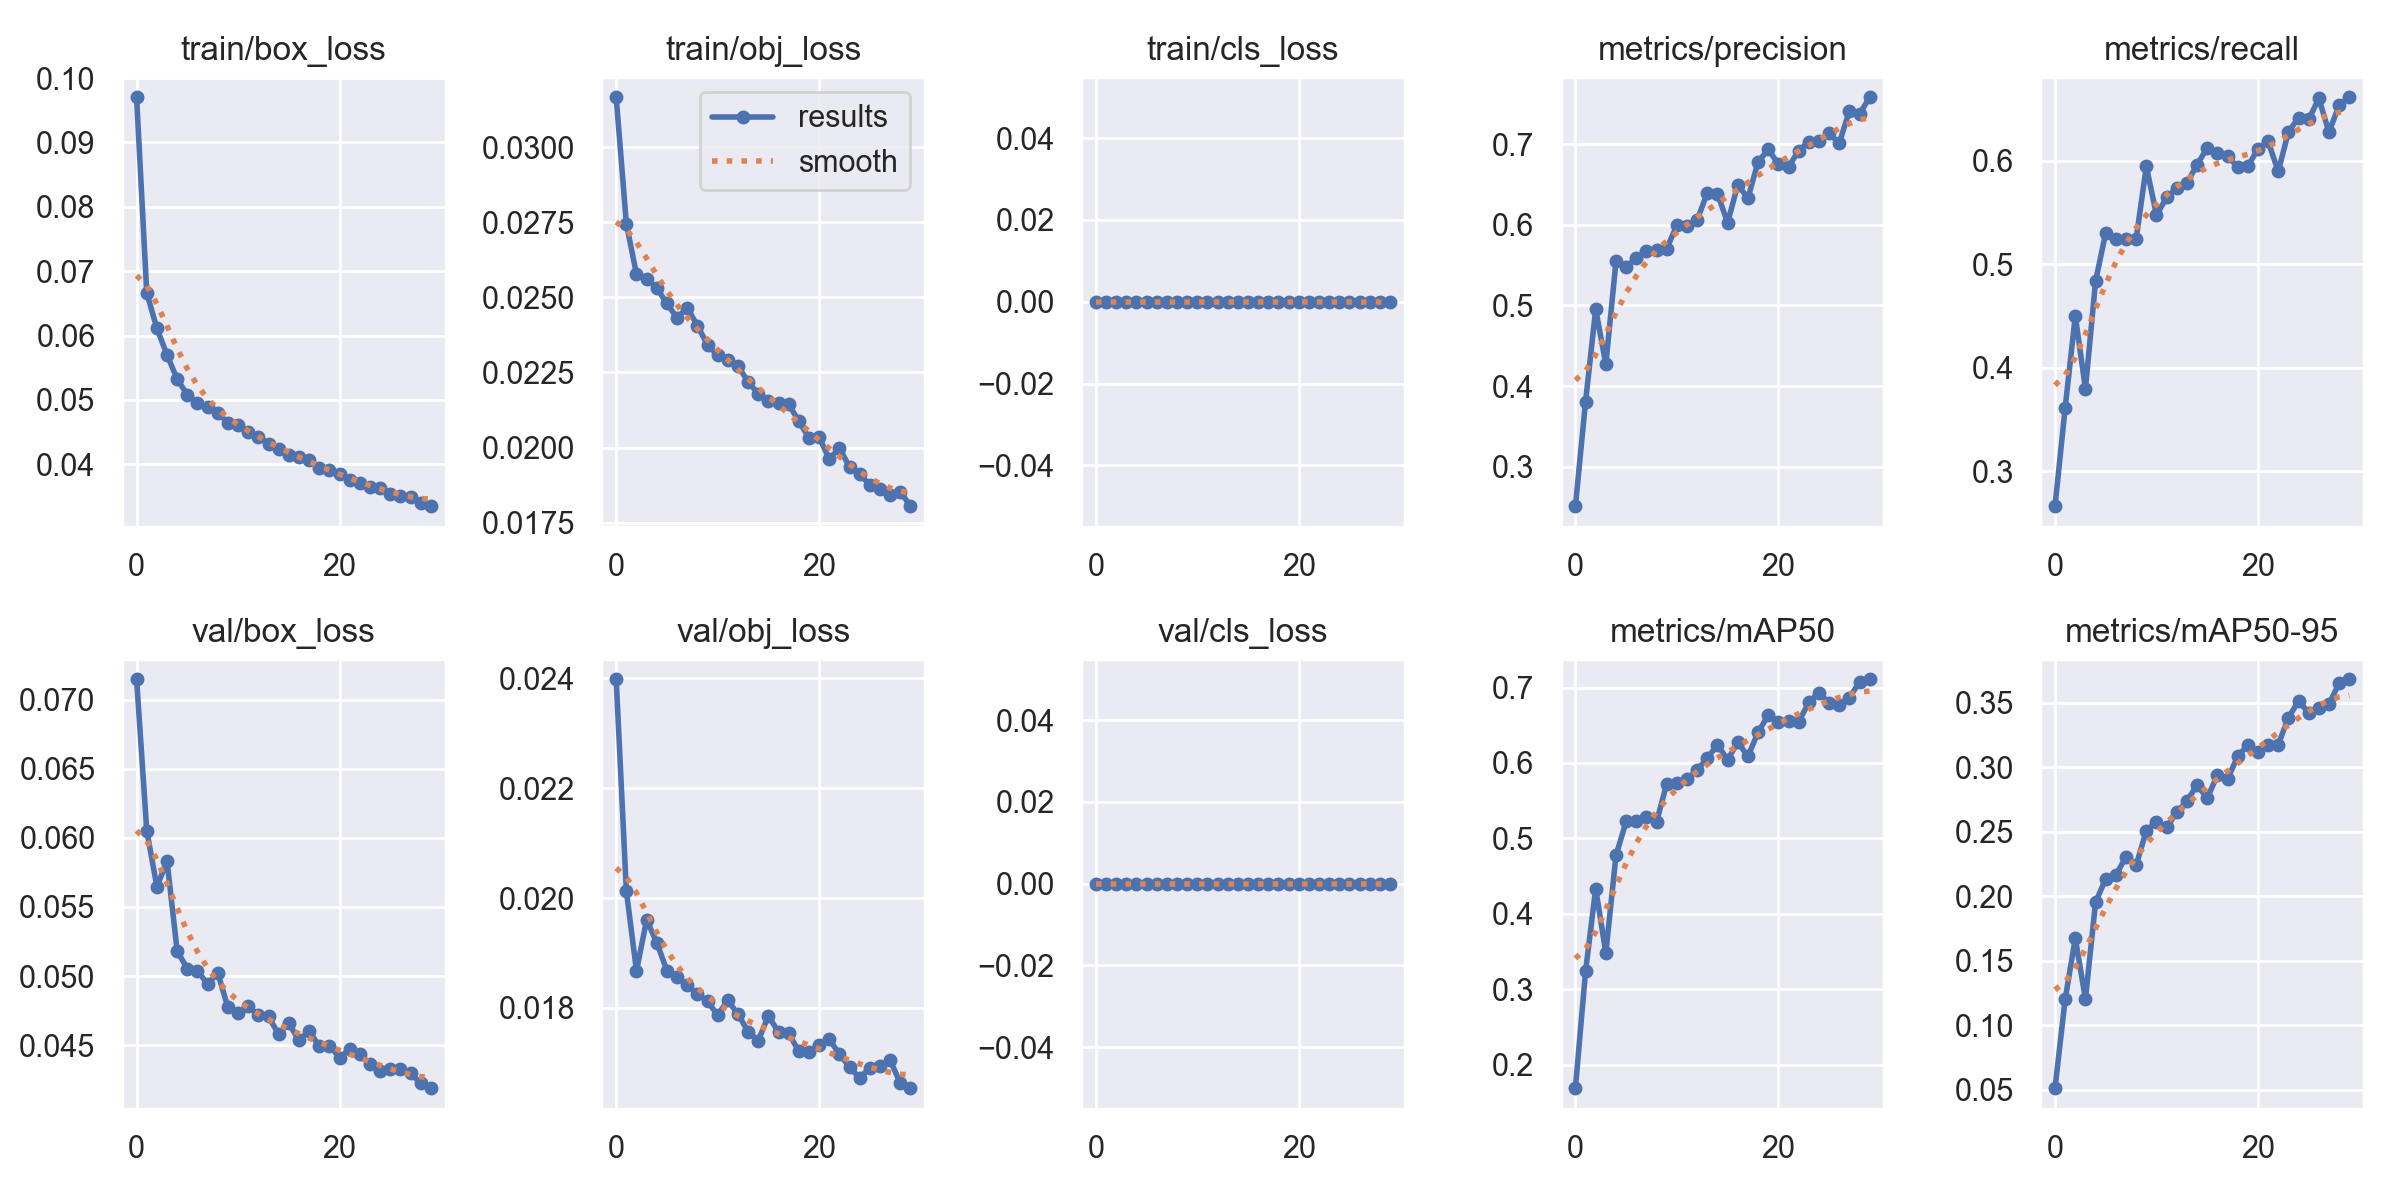

MA TRAN NHAM LAN (CONFUSION MATRIX):


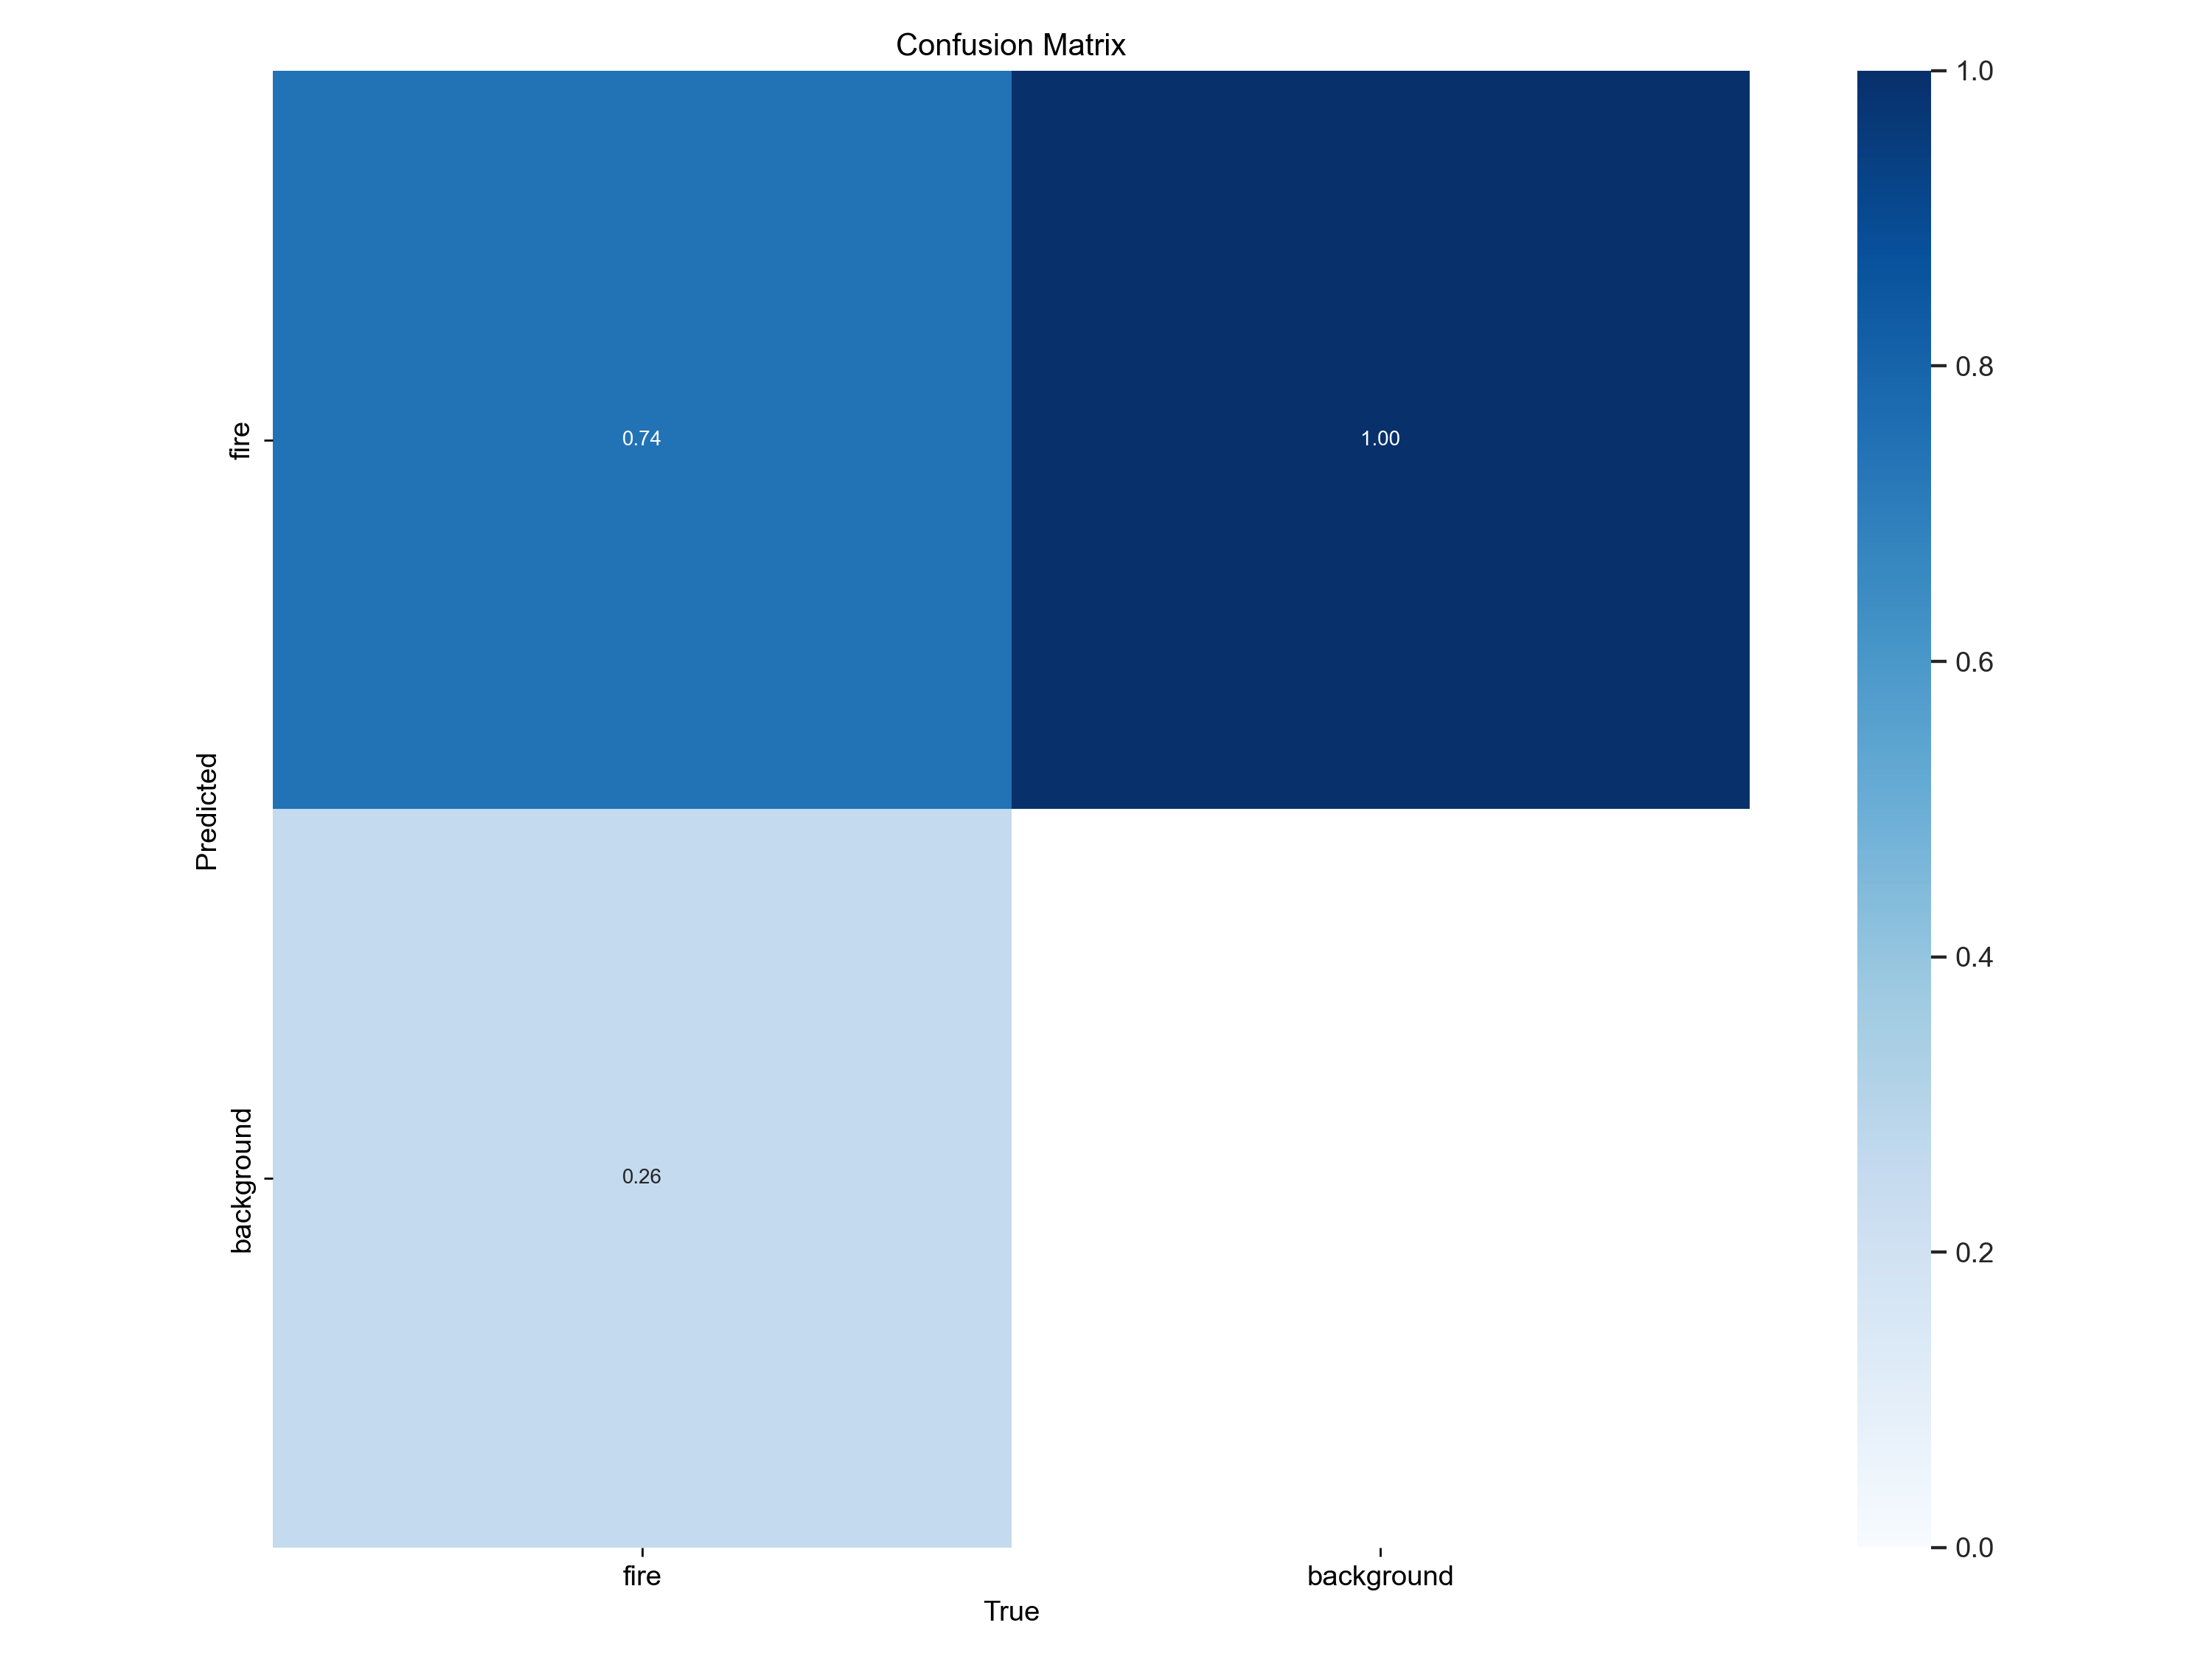

In [ ]:
print("BIEU DO KET QUA THI NGHIEM 1 (BASELINE):")
display(Image('runs/train/exp1_baseline/results.png', width=900))

print("MA TRAN NHAM LAN (CONFUSION MATRIX):")
display(Image('runs/train/exp1_baseline/confusion_matrix.png', width=600))


# Nhan xet
1. Danh gia ket qua

Mo hinh da nhan dien duoc doi tuong fire voi ty le khoang 74%.

Con khoang 26% doi tuong fire bi bo sot.

Ty le background bi nhan nham thanh fire la 100% theo ma tran chuan hoa, cho thay kha nang phan biet giua lua va moi truong xung quanh con kem.

Mo hinh chua du on dinh de trien khai thuc te do nguy co canh bao chay gia cao.


### [Buoc 7] THI NGHIEM 2: TINH CHINH THAM SO (EXP2_TUNING)
Dua tren chan doan o Thi nghiem 1, tien hanh tinh chinh:
- Giam learning rate ban dau (lr0 = 0.005) de mo hinh hoi tu min hon.
- Giam cuong do mosaic xuong 0.7 va tat mixup (0.0) de giu nguyen ven dac trung lua.
- Tang kich thuoc anh len 768x768 de phat hien tot hon cac dom lua nho o xa.
- Bat Cosine Learning Rate Scheduler (--cos-lr) va Early Stopping (--patience 20).
Luu ket qua tai: runs/train/exp2_tuning


In [ ]:
import yaml

hyp_path = "data/hyps/hyp.scratch-low.yaml"

with open(hyp_path, "r") as f:
    hyp = yaml.safe_load(f)

hyp["lr0"] = 0.005
hyp["lrf"] = 0.01
hyp["mosaic"] = 0.7
hyp["mixup"] = 0.0

with open("hyp_fire.yaml", "w") as f:
    yaml.safe_dump(hyp, f, sort_keys=False)

print("Da tao file cau hinh sieu tham so hyp_fire.yaml thanh cong.")


Da tao file cau hinh sieu tham so hyp_fire.yaml thanh cong.


In [ ]:
!python train.py \
  --img 768 \
  --batch 16 \
  --epochs 40 \
  --data fire.yaml \
  --weights yolov5s.pt \
  --hyp hyp_fire.yaml \
  --name exp2_tuning \
  --workers 2 \
  --cache \
  --cos-lr \
  --patience 20


WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1795356921.671648   10908 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
train: weights=yolov5s.pt, cfg=, data=fire.yaml, hyp=hyp_fire.yaml, epochs=40, batch_size=16, imgsz=768, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=ram, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=2, project=runs/train, name=exp2_tuning, exist_ok=False, quad=False, cos_lr=True, label_smoothing=0.0, patience=20, freeze=[0], save_period=-1, seed=0, local_rank=-1, entity=None, upload_dataset=False, bbox_interval=-1
github: up to date with https://github.com/ultralytics/yolov5 ✅
YOLOv5 🚀 v7.0-574-g1e7cf74c Python-3.13.16 torch-2.1

### [Buoc 7B] THI NGHIEM 3: YOLOv8n (mo hinh so sanh)
Huan luyen YOLOv8n tren **cung dataset_clean** de so sanh voi YOLOv5s (Exp 1, Exp 2).
- Cau hinh cong bang voi Exp 1: imgsz=640, batch=16, epochs=30, workers=2, cache.
- Dung cac sieu tham so mac dinh cua Ultralytics (khong tinh chinh them) de so sanh "mac dinh vs mac dinh".
- Ket qua luu tai: runs/train/exp3_yolov8n (cung thu muc voi Exp 1, Exp 2).

In [ ]:
%pip install -q ultralytics
%env WANDB_MODE=disabled

# File cau hinh dataset cho Ultralytics (cung du lieu voi fire.yaml cua YOLOv5)
yaml_v8 = """
path: /content/dataset_clean
train: train/images
val: val/images
test: test/images

names:
  0: fire
"""
with open('/content/fire_v8.yaml', 'w') as f:
    f.write(yaml_v8.strip())

import ultralytics
ultralytics.checks()
print('Da tao /content/fire_v8.yaml')

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 3.8/112.6 GB disk)
Da tao /content/fire_v8.yaml


YOLOv8n Baseline

In [ ]:
%cd /content
!yolo detect train \
  model=yolov8n.pt \
  data=/content/fire_v8.yaml \
  imgsz=640 \
  batch=16 \
  epochs=30 \
  workers=2 \
  cache=True \
  project=/content/yolov5/runs/train \
  name=exp3_yolov8n \
  exist_ok=True

# Quay lai thu muc yolov5 de cac buoc sau (duong dan tuong doi) van chay dung
%cd /content/yolov5

/content
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/fire_v8.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=exp3_yolov8n, nbs=64, nms=None, opset=None, optimize=False, 

YOLOv8n Tuning

In [ ]:

%cd /content

!yolo detect train \
  model=yolov8n.pt \
  data=/content/fire_v8.yaml \
  imgsz=768 \
  batch=16 \
  epochs=40 \
  workers=2 \
  cache=True \
  lr0=0.005 \
  lrf=0.01 \
  mosaic=0.7 \
  mixup=0.0 \
  cos_lr=True \
  patience=20 \
  seed=42 \
  project=/content/yolov5/runs/train \
  name=exp4_yolov8n_tuning \
  exist_ok=True

%cd /content/yolov5


/content
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/fire_v8.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=768, iou=None, kobj=1.0, line_width=None, lr0=0.005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=0.7, multi_scale=0.0, name=exp4_yolov8n_tuning, nbs=64, nms=None, opset=None, optimize=

### [Buoc 8] BANG SO SANH HIEU NANG DAY DU (P, R, F1-SCORE, mAP) CHO BAO CAO
Trich xuat so lieu tu file results.csv cua ca 2 thi nghiem: exp1_baseline va exp2_tuning.


BANG SO SANH HIEU NANG GIUA 2 THI NGHIEM:


,Thi nghiem,Best Epoch,Precision,Recall,F1-Score (%),mAP@0.5 (%),mAP@0.5:0.95 (%),Val Box Loss,Val Obj Loss
0,exp1_baseline,29,0.7582,0.6613,70.65,71.11,36.84,0.0419,0.0165
1,exp2_tuning,38,0.7626,0.6537,70.40,70.54,36.77,0.0406,0.0184



So sanh bieu do ket qua huan luyen:
--> Bieu do Exp 1 (Baseline):


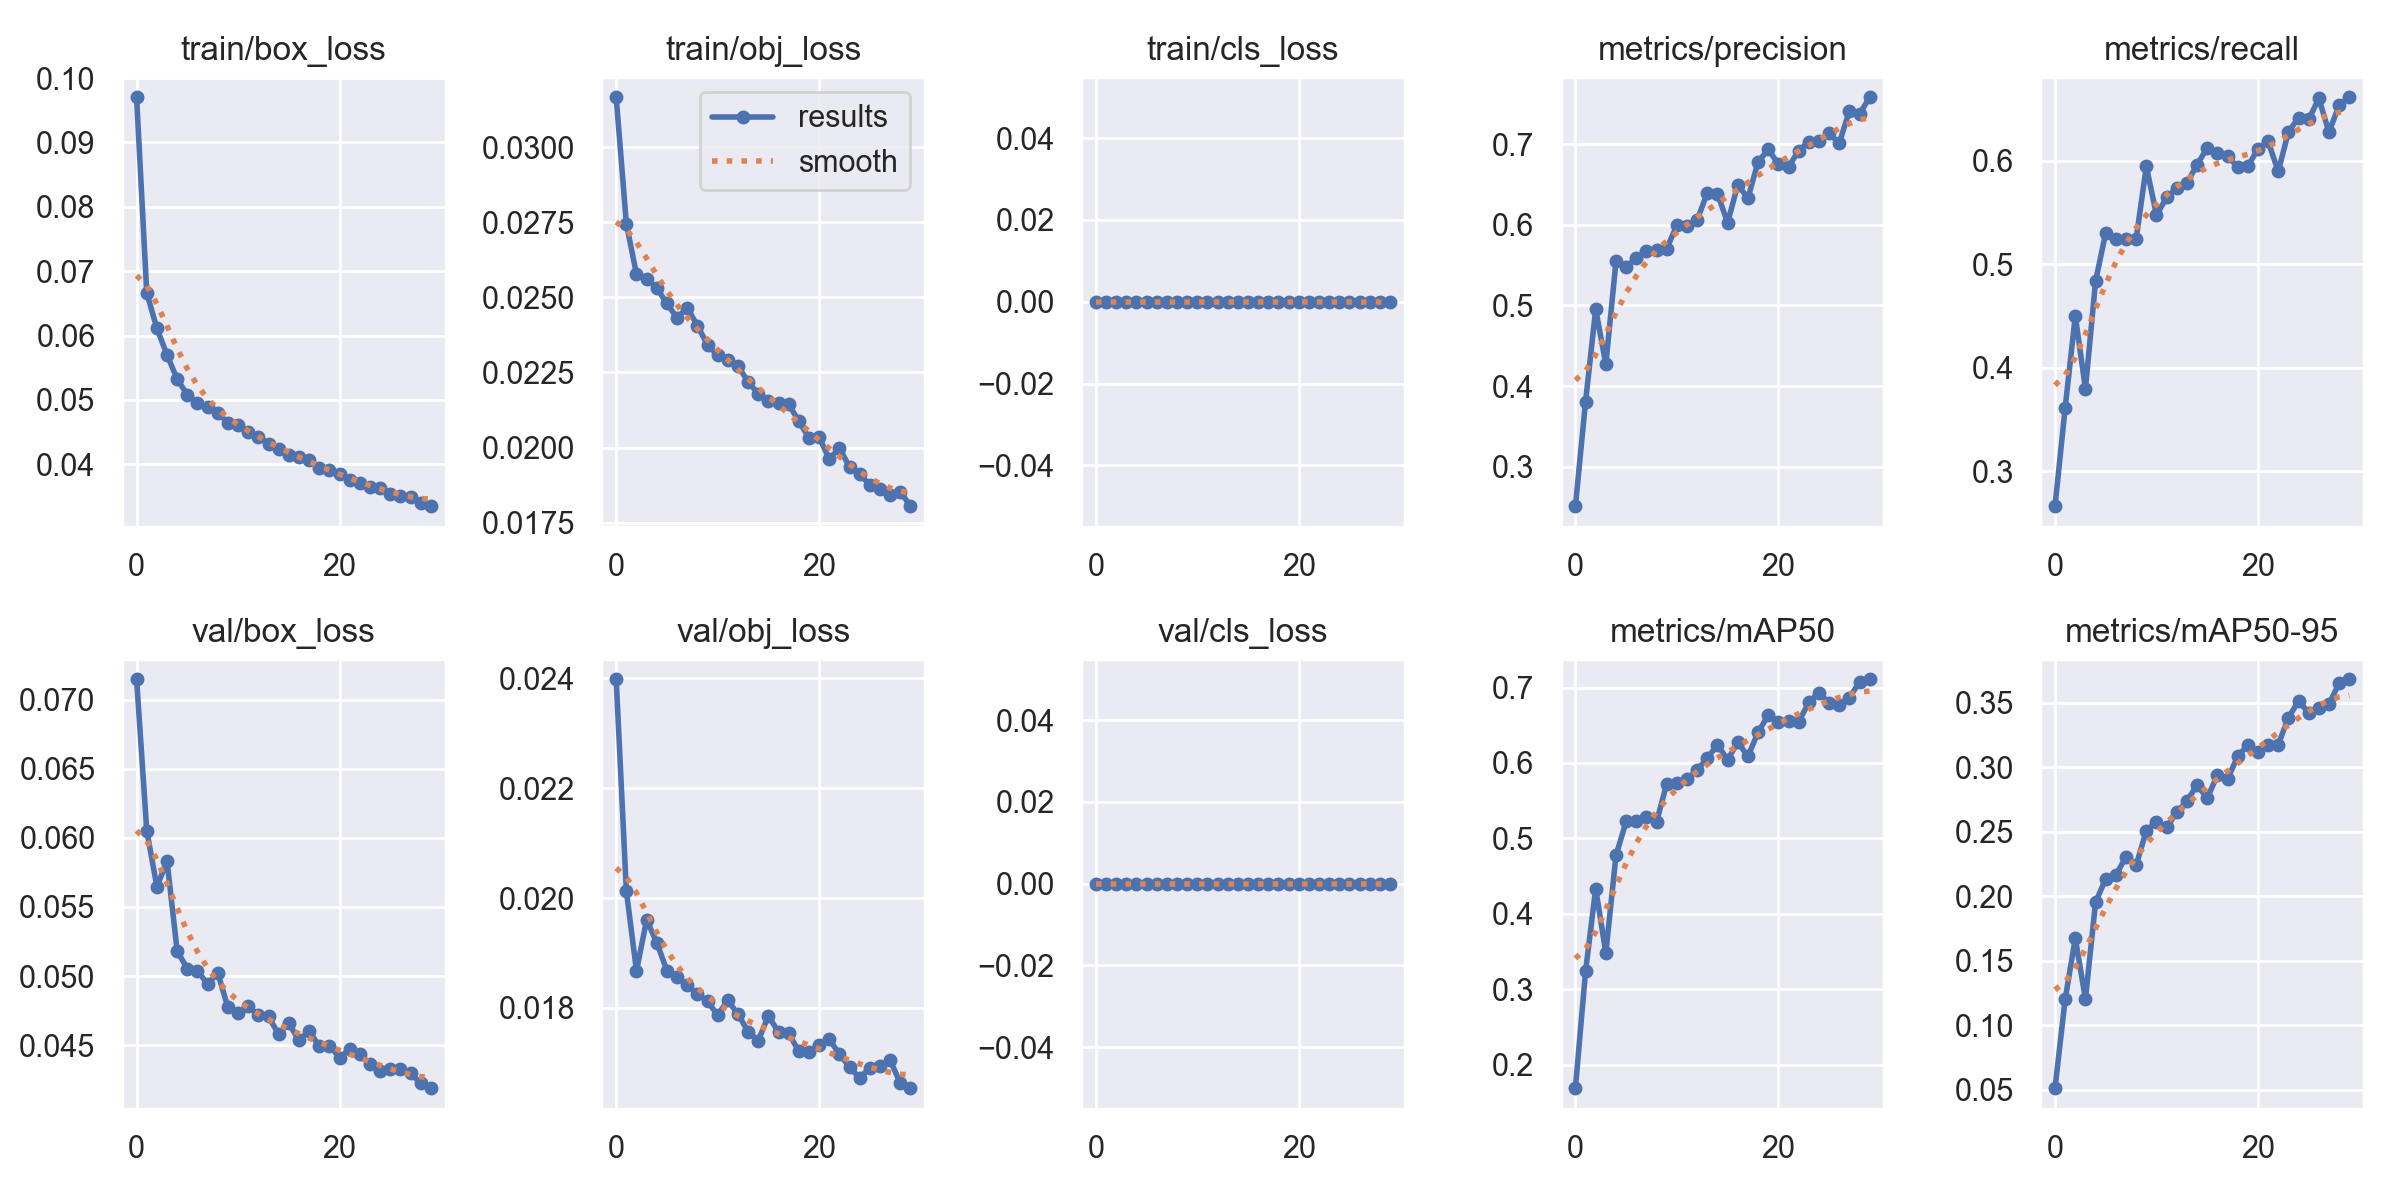

--> Bieu do Exp 2 (Tuning):


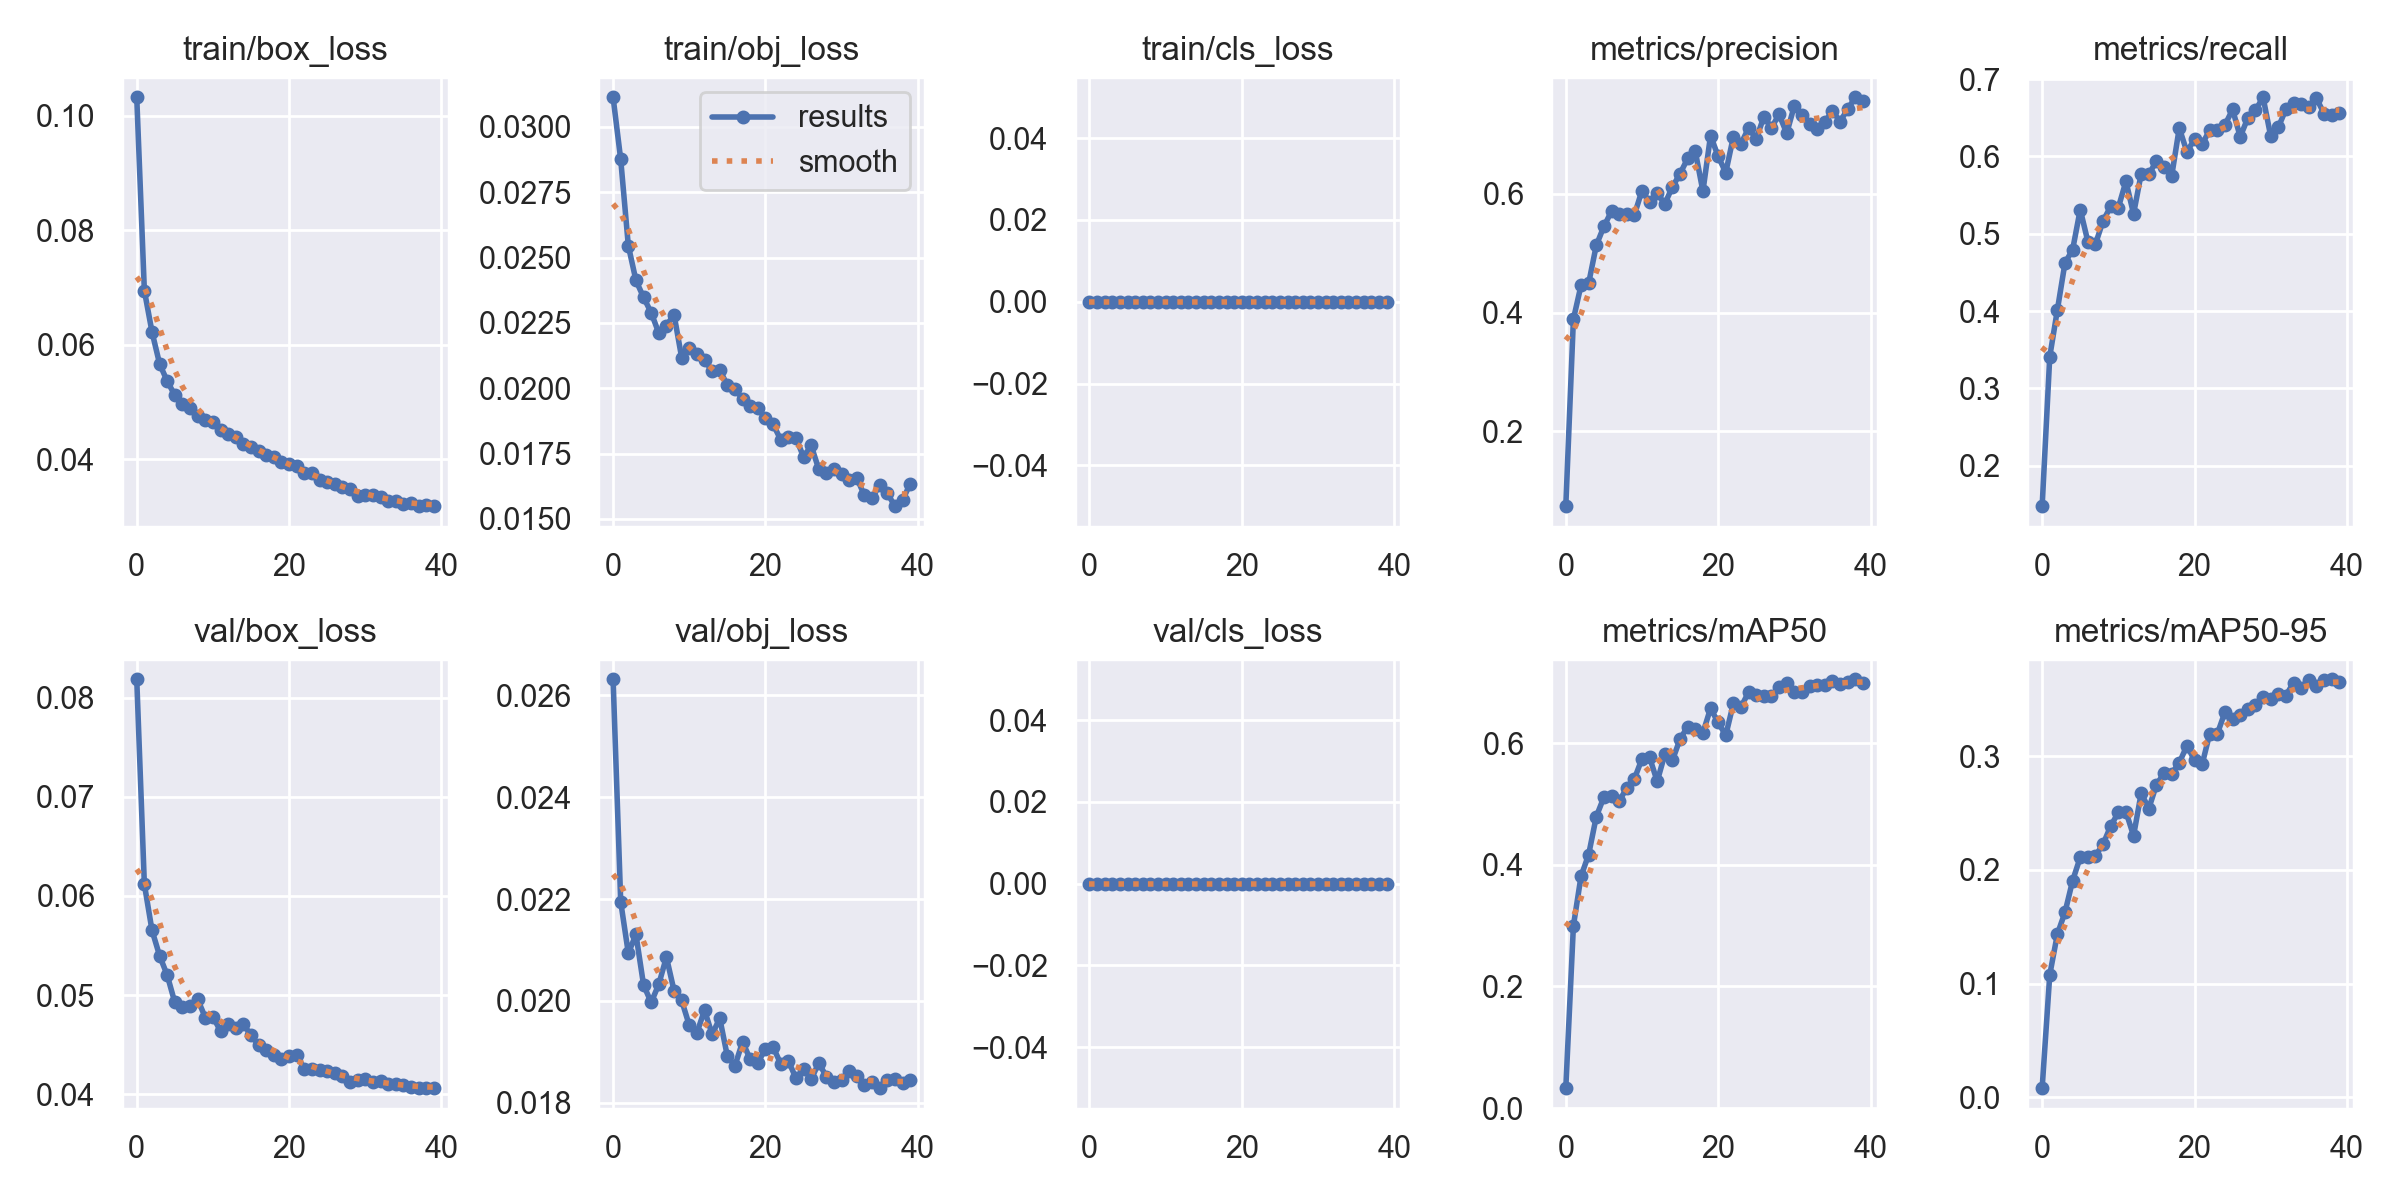

In [ ]:
import pandas as pd
import os

def get_best_metrics(exp_name):
    csv_path = f'runs/train/{exp_name}/results.csv'
    if not os.path.exists(csv_path):
        return None
    df = pd.read_csv(csv_path)
    df.columns = [c.strip() for c in df.columns]

    # Lay dong co mAP50 cao nhat
    col_map50 = 'metrics/mAP50' if 'metrics/mAP50' in df.columns else 'metrics/mAP_0.5'
    col_map95 = 'metrics/mAP50-95' if 'metrics/mAP50-95' in df.columns else 'metrics/mAP_0.5:0.95'
    col_p = 'metrics/precision'
    col_r = 'metrics/recall'

    best_row = df.loc[df[col_map50].idxmax()]
    p = best_row[col_p]
    r = best_row[col_r]
    f1 = (2 * p * r) / (p + r) if (p + r) > 0 else 0

    return {
        'Thi nghiem': exp_name,
        'Best Epoch': int(best_row['epoch']),
        'Precision': round(p, 4),
        'Recall': round(r, 4),
        'F1-Score (%)': round(f1 * 100, 2),
        'mAP@0.5 (%)': round(best_row[col_map50] * 100, 2),
        'mAP@0.5:0.95 (%)': round(best_row[col_map95] * 100, 2),
        'Val Box Loss': round(best_row['val/box_loss'], 4),
        'Val Obj Loss': round(best_row['val/obj_loss'], 4)
    }

results = []
for exp in ['exp1_baseline', 'exp2_tuning']:
    m = get_best_metrics(exp)
    if m:
        results.append(m)

summary_df = pd.DataFrame(results)
print("=" * 80)
print("BANG SO SANH HIEU NANG GIUA 2 THI NGHIEM:")
print("=" * 80)
display(summary_df)

print("\nSo sanh bieu do ket qua huan luyen:")
col1_path = 'runs/train/exp1_baseline/results.png'
col2_path = 'runs/train/exp2_tuning/results.png'
if os.path.exists(col1_path):
    print("--> Bieu do Exp 1 (Baseline):")
    display(Image(col1_path, width=750))
if os.path.exists(col2_path):
    print("--> Bieu do Exp 2 (Tuning):")
    display(Image(col2_path, width=750))


### [Buoc 8B] SO SANH 3 MO HINH TREN TAP VAL (YOLOv5s baseline, YOLOv5s tuning, YOLOv8n)
Doc results.csv cua ca 3 thi nghiem (ten cot cua YOLOv5 va YOLOv8 khac nhau nen xu ly rieng), lay epoch co mAP@0.5 cao nhat.

BANG SO SANH TREN TAP VAL (epoch tot nhat theo mAP@0.5):


,Mo hinh,Best Epoch,Precision,Recall,F1-Score (%),mAP@0.5 (%),mAP@0.5:0.95 (%),Val Box Loss
0,YOLOv5s (Exp1 baseline),30,0.7582,0.6613,70.65,71.11,36.84,0.0419
1,YOLOv5s (Exp2 tuning),39,0.7626,0.6537,70.40,70.54,36.77,0.0406
2,YOLOv8n (Exp3),30,0.6340,0.5896,61.10,61.57,31.66,1.6161


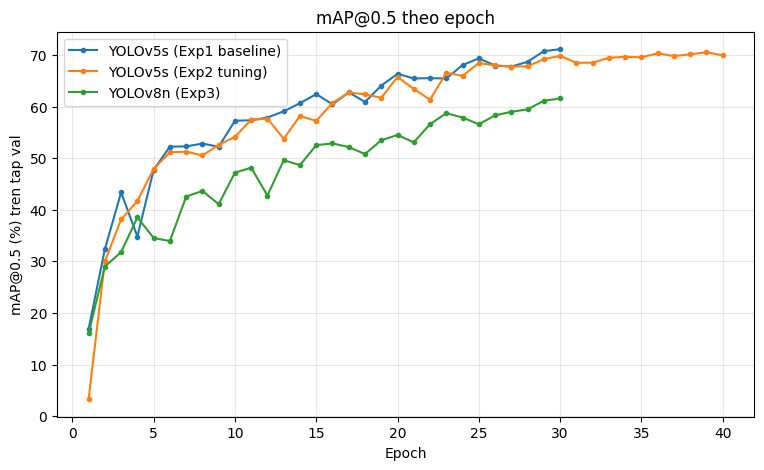

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

EXPS = [
    ('exp1_baseline', 'YOLOv5s (Exp1 baseline)', 'v5'),
    ('exp2_tuning',   'YOLOv5s (Exp2 tuning)',   'v5'),
    ('exp3_yolov8n',  'YOLOv8n (Exp3)',          'v8'),
]

def load_results(exp):
    df = pd.read_csv(f'/content/yolov5/runs/train/{exp}/results.csv')
    df.columns = [c.strip() for c in df.columns]
    return df

def pick(df, *names):
    for n in names:
        if n in df.columns:
            return n
    raise KeyError(f'Khong tim thay cot nao trong {names}')

rows = []
curves = {}
for exp, label, fam in EXPS:
    try:
        df = load_results(exp)
    except FileNotFoundError:
        print(f'Bo qua {exp}: chua co results.csv')
        continue
    c50 = pick(df, 'metrics/mAP50', 'metrics/mAP_0.5', 'metrics/mAP50(B)')
    c95 = pick(df, 'metrics/mAP50-95', 'metrics/mAP_0.5:0.95', 'metrics/mAP50-95(B)')
    cp  = pick(df, 'metrics/precision', 'metrics/precision(B)')
    cr  = pick(df, 'metrics/recall', 'metrics/recall(B)')

    best = df.loc[df[c50].idxmax()]
    p, r = best[cp], best[cr]
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0
    # results.csv cua YOLOv5 danh epoch tu 0, cua YOLOv8 tu 1 -> quy ve tu 1
    best_epoch = int(best['epoch']) + (1 if fam == 'v5' else 0)

    rows.append({
        'Mo hinh': label,
        'Best Epoch': best_epoch,
        'Precision': round(p, 4),
        'Recall': round(r, 4),
        'F1-Score (%)': round(f1 * 100, 2),
        'mAP@0.5 (%)': round(best[c50] * 100, 2),
        'mAP@0.5:0.95 (%)': round(best[c95] * 100, 2),
        'Val Box Loss': round(best['val/box_loss'], 4),
    })
    x = df['epoch'] + (1 if fam == 'v5' else 0)
    curves[label] = (x, df[c50] * 100)

val_df = pd.DataFrame(rows)
print('=' * 80)
print('BANG SO SANH TREN TAP VAL (epoch tot nhat theo mAP@0.5):')
print('=' * 80)
display(val_df)

# Duong cong mAP@0.5 theo epoch
plt.figure(figsize=(9, 5))
for label, (x, y) in curves.items():
    plt.plot(x, y, marker='o', markersize=3, label=label)
plt.xlabel('Epoch')
plt.ylabel('mAP@0.5 (%) tren tap val')
plt.title('mAP@0.5 theo epoch')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### [Buoc 9] Danh gia va suy luan (Inference) tren tap TEST doc lap (553 anh)
Tu dong lua chon mo hinh co chi so mAP cao nhat giua Exp 1 va Exp 2 de thuc hien kiem thu.


mAP@0.5 Exp 1: 71.11% | Exp 2: 70.53%
Mo hinh dat do chinh xac cao nhat: Exp 1 (Baseline)
Duong dan mo hinh: runs/train/exp1_baseline/weights/best.pt
val: data=fire.yaml, weights=['runs/train/exp1_baseline/weights/best.pt'], batch_size=32, imgsz=640, conf_thres=0.25, iou_thres=0.6, max_det=300, task=test, device=, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=runs/val, name=eval_test_set, exist_ok=False, half=False, dnn=False
WARNING ⚠️ confidence threshold 0.25 > 0.001 produces invalid results
YOLOv5 🚀 v7.0-574-g1e7cf74c Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,012,822 parameters, 0 gradients, 15.8 GFLOPs
test: Scanning /content/dataset_clean/test/labels... 603 images, 50 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 603/603 343.5it/s 1.8s
test: New cache created: /content/dataset_clean/test/labels.cache
                 Class     Im

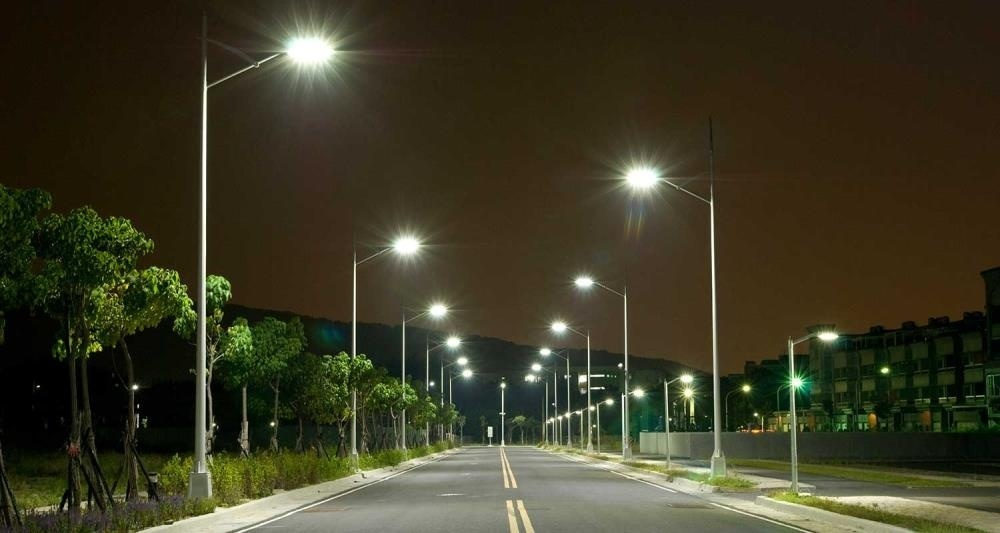

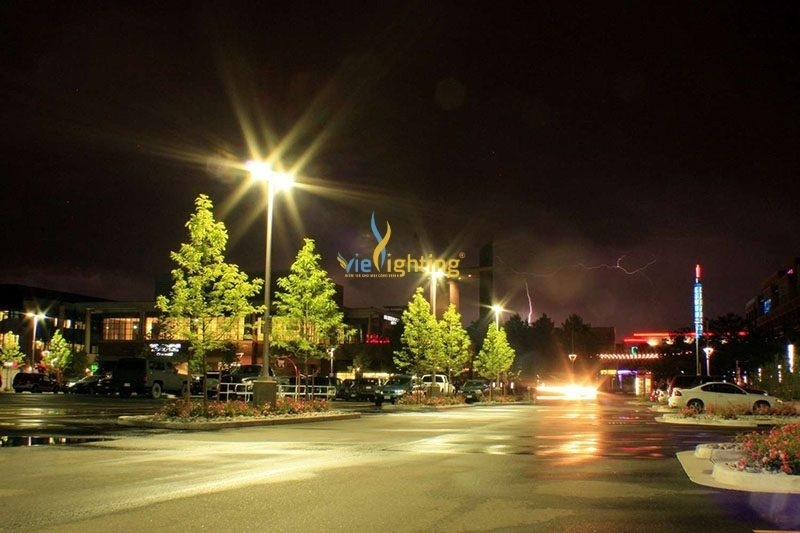

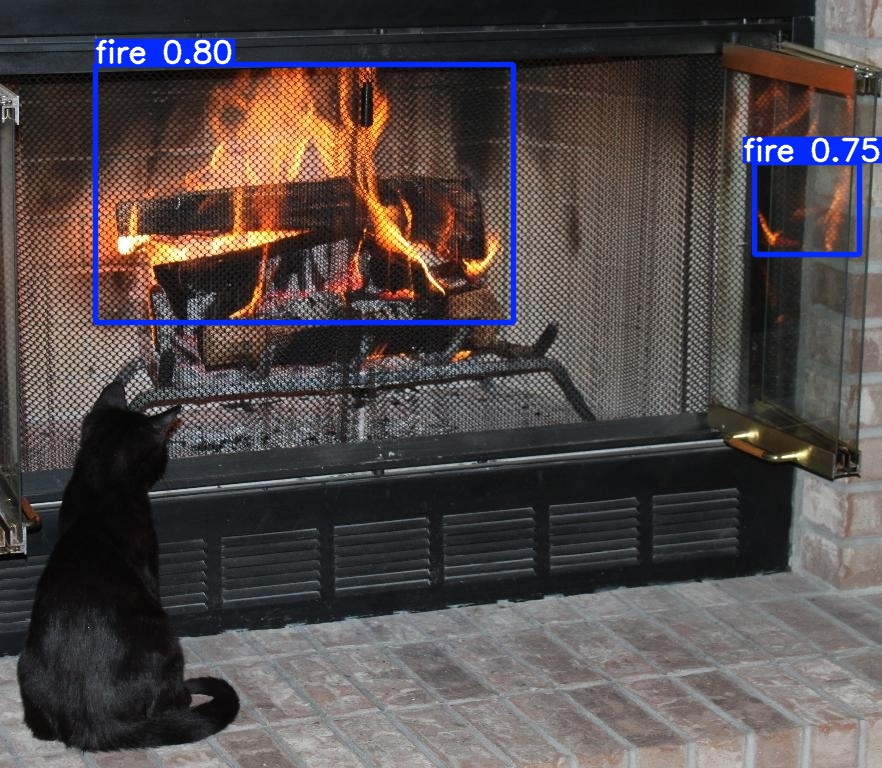

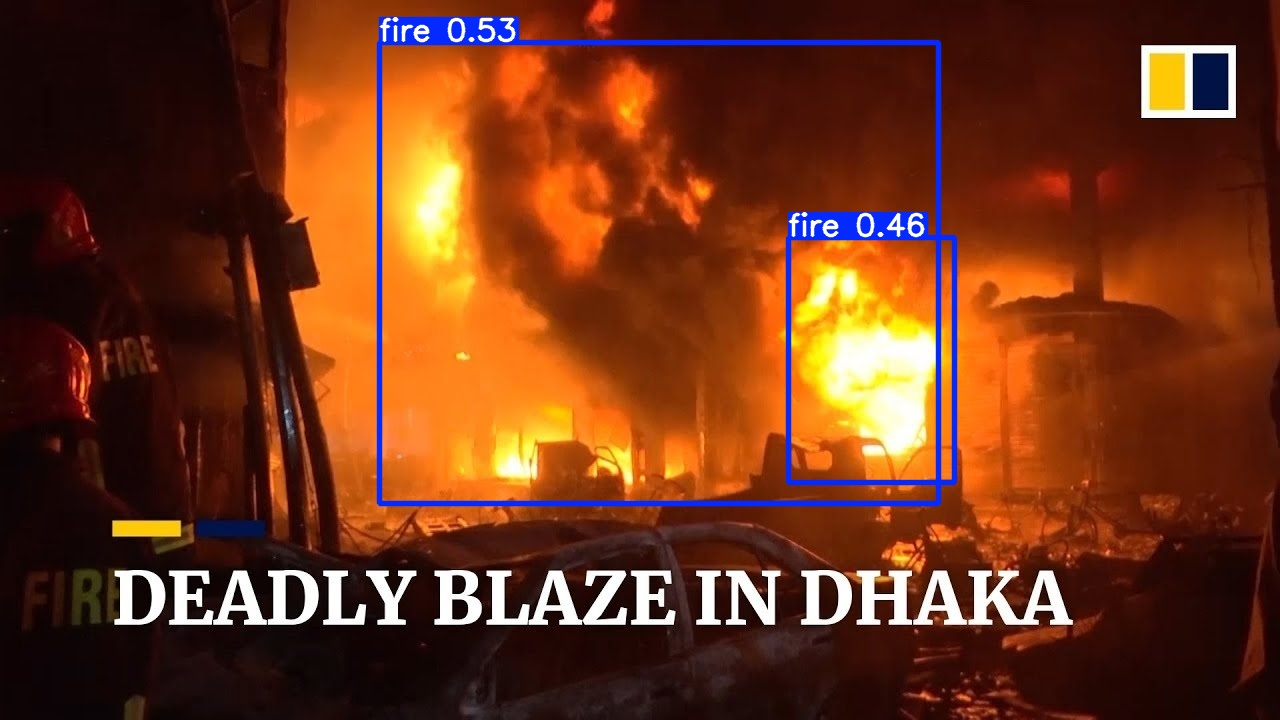

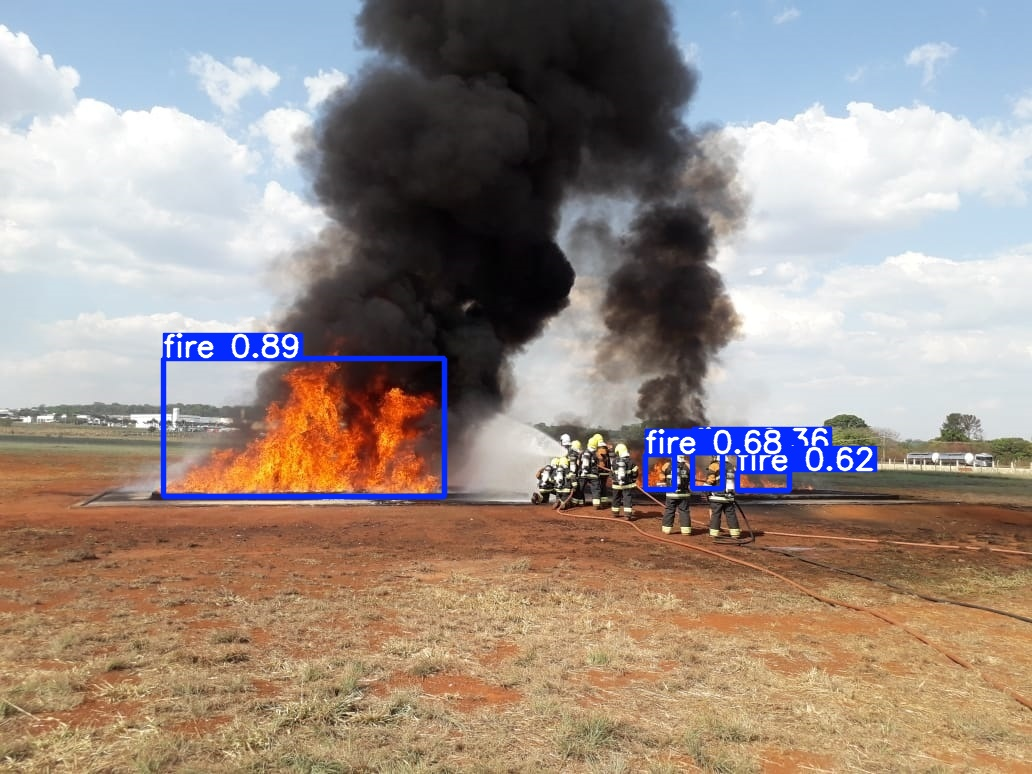

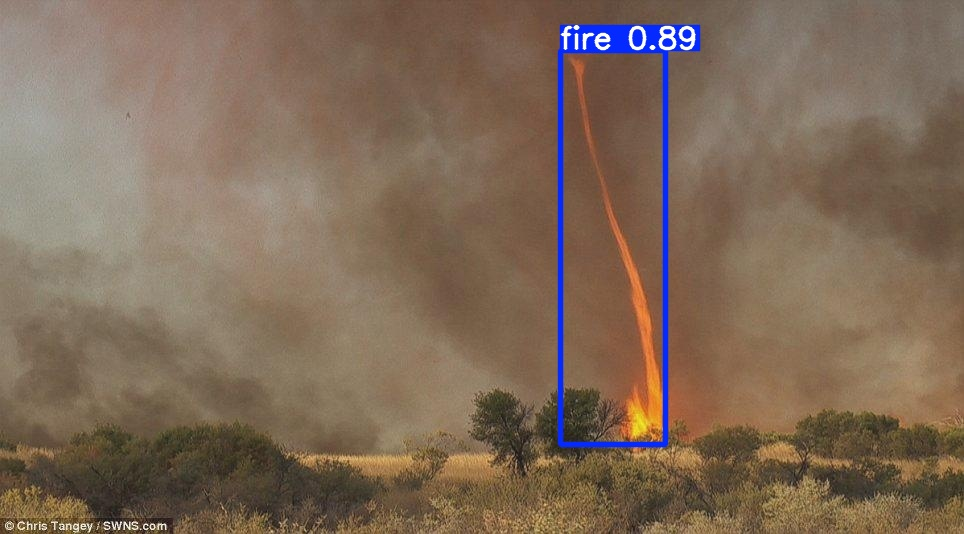

In [ ]:
# Tu dong so sanh mAP de chon mo hinh tot nhat
import os
import pandas as pd

def get_map(exp):
    csv_p = f'runs/train/{exp}/results.csv'
    if os.path.exists(csv_p):
        df = pd.read_csv(csv_p)
        df.columns = [c.strip() for c in df.columns]
        col_map = 'metrics/mAP50' if 'metrics/mAP50' in df.columns else 'metrics/mAP_0.5'
        return df[col_map].max()
    return 0.0

map_exp1 = get_map('exp1_baseline')
map_exp2 = get_map('exp2_tuning')

print(f"mAP@0.5 Exp 1: {map_exp1 * 100:.2f}% | Exp 2: {map_exp2 * 100:.2f}%")

if map_exp2 >= map_exp1 and os.path.exists('runs/train/exp2_tuning/weights/best.pt'):
    best_model_path = 'runs/train/exp2_tuning/weights/best.pt'
    winner = 'Exp 2 (Tuning)'
elif os.path.exists('runs/train/exp1_baseline/weights/best.pt'):
    best_model_path = 'runs/train/exp1_baseline/weights/best.pt'
    winner = 'Exp 1 (Baseline)'
else:
    best_model_path = 'runs/train/exp2_tuning/weights/best.pt'
    winner = 'Exp 2 (Tuning)'

print(f"Mo hinh dat do chinh xac cao nhat: {winner}")
print(f"Duong dan mo hinh: {best_model_path}")

# Danh gia dinh luong tren tap test (task=test)
!python val.py --weights {best_model_path} --data fire.yaml --task test --img 640 --conf 0.25 --name eval_test_set

# Suy luan tren tap anh test (Inference)
!python detect.py --weights {best_model_path} --source /content/dataset_clean/test/images --img 640 --conf 0.35 --name detect_test_samples

import glob
from IPython.display import Image, display
sample_preds = glob.glob('runs/detect/detect_test_samples/*.jpg')[:6]
for p in sample_preds:
    display(Image(filename=p, width=500))


### [Buoc 9B] SO SANH 3 MO HINH TREN TAP TEST DOC LAP (553 anh)
Danh gia ca 3 mo hinh voi **cung nguong conf va IoU** tren tap test, dong thoi do kich thuoc mo hinh (so tham so, GFLOPs) va toc do suy luan.
- Moi mo hinh duoc danh gia o dung kich thuoc anh luc huan luyen (Exp1: 640, Exp2: 768, Exp3: 640).
- CONF_THRES = 0.25 giong Buoc 9, nen mAP thap hon so lieu chuan (conf = 0.001). Co the doi o dau cell.
- Toc do chi mang tinh tham khao (do tren GPU Colab, batch 32).

>>> Dang danh gia YOLOv5s (Exp1 baseline) tren tap test...
>>> Dang danh gia YOLOv5s (Exp2 tuning) tren tap test...
>>> Dang danh gia YOLOv8n (Exp3 baseline) tren tap test...
>>> Dang danh gia YOLOv8n (Exp4 tuning) tren tap test...
BANG SO SANH TREN TAP TEST (conf=0.25, iou=0.6):


,Mo hinh,imgsz,Precision,Recall,F1-Score (%),mAP@0.5 (%),mAP@0.5:0.95 (%),Params (M),GFLOPs,Inference (ms/anh)
0,YOLOv5s (Exp1 baseline),640,0.687,0.653,66.96,69.0,39.0,7.01,15.8,4.5
1,YOLOv5s (Exp2 tuning),768,0.728,0.629,67.49,68.9,39.8,7.01,15.8,6.9
2,YOLOv8n (Exp3 baseline),640,0.615,0.600,60.74,49.6,25.1,3.13,8.6,3.0
3,YOLOv8n (Exp4 tuning),768,0.653,0.589,61.94,52.5,27.5,3.13,8.6,4.3


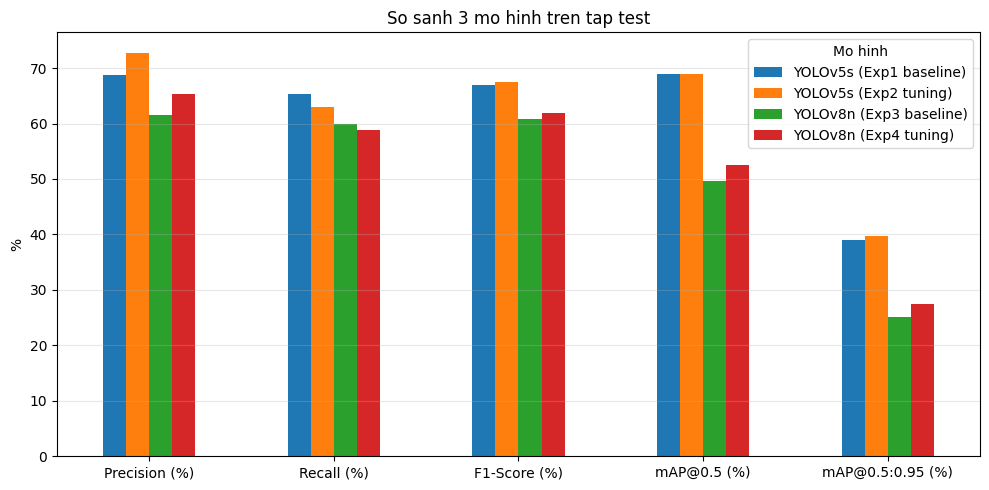

In [ ]:
import re, subprocess
import pandas as pd
import matplotlib.pyplot as plt

CONF_THRES = 0.25
IOU_THRES = 0.6   # mac dinh cua YOLOv5 val.py, dat chung cho YOLOv8 de cong bang

# TEST_MODELS = [
#     # (ten hien thi, ho, duong dan trong so, imgsz luc train, tag)
#     ('YOLOv5s (Exp1 baseline)', 'v5', '/content/yolov5/runs/train/exp1_baseline/weights/best.pt', 640, 'exp1'),
#     ('YOLOv5s (Exp2 tuning)',   'v5', '/content/yolov5/runs/train/exp2_tuning/weights/best.pt',   768, 'exp2'),
#     ('YOLOv8n (Exp3)',          'v8', '/content/yolov5/runs/train/exp3_yolov8n/weights/best.pt',  640, 'exp3'),
# ]
TEST_MODELS = [
    ('YOLOv5s (Exp1 baseline)', 'v5',
     '/content/yolov5/runs/train/exp1_baseline/weights/best.pt', 640, 'exp1'),

    ('YOLOv5s (Exp2 tuning)', 'v5',
     '/content/yolov5/runs/train/exp2_tuning/weights/best.pt', 768, 'exp2'),

    ('YOLOv8n (Exp3 baseline)', 'v8',
     '/content/yolov5/runs/train/exp3_yolov8n/weights/best.pt', 640, 'exp3'),

    ('YOLOv8n (Exp4 tuning)', 'v8',
     '/content/yolov5/runs/train/exp4_yolov8n_tuning/weights/best.pt', 768, 'exp4'),
]

def run_cmd(cmd, cwd):
    p = subprocess.run(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                       text=True, cwd=cwd)
    text = re.sub(r'\x1b\[[0-9;?]*[A-Za-z]', '', p.stdout)
    return text.replace('\r', '\n')

def parse_output(text):
    m = re.search(r'^\s*all\s+\d+\s+\d+\s+(\S+)\s+(\S+)\s+(\S+)\s+(\S+)', text, re.M)
    if not m:
        return None
    p, r, m50, m95 = map(float, m.groups())
    params = re.search(r'([\d,]+) parameters,\s*[\d,]+ gradients,\s*([\d.]+) GFLOPs', text)
    speed = re.search(r'([\d.]+)ms inference', text)
    return {
        'p': p, 'r': r, 'm50': m50, 'm95': m95,
        'params': int(params.group(1).replace(',', '')) if params else None,
        'gflops': float(params.group(2)) if params else None,
        'ms': float(speed.group(1)) if speed else None,
    }

test_rows = []
for label, fam, weights, imgsz, tag in TEST_MODELS:
    if not os.path.exists(weights):
        print(f'Bo qua {label}: khong thay {weights}')
        continue
    print(f'>>> Dang danh gia {label} tren tap test...')
    if fam == 'v5':
        cmd = (f'python val.py --weights {weights} --data fire.yaml --task test --img {imgsz} '
               f'--batch-size 32 --conf-thres {CONF_THRES} --iou-thres {IOU_THRES} '
               f'--name cmp_test_{tag} --exist-ok')
        out = run_cmd(cmd, '/content/yolov5')
    else:
        cmd = (f'yolo detect val model={weights} data=/content/fire_v8.yaml split=test imgsz={imgsz} '
               f'batch=32 conf={CONF_THRES} iou={IOU_THRES} plots=False '
               f'project=/content/yolov5/runs/val name=cmp_test_{tag} exist_ok=True')
        out = run_cmd(cmd, '/content')

    res = parse_output(out)
    if res is None:
        print('Khong doc duoc ket qua, 40 dong cuoi cua log:')
        print('\n'.join(out.splitlines()[-40:]))
        continue

    f1 = 2 * res['p'] * res['r'] / (res['p'] + res['r']) if (res['p'] + res['r']) > 0 else 0
    test_rows.append({
        'Mo hinh': label,
        'imgsz': imgsz,
        'Precision': round(res['p'], 4),
        'Recall': round(res['r'], 4),
        'F1-Score (%)': round(f1 * 100, 2),
        'mAP@0.5 (%)': round(res['m50'] * 100, 2),
        'mAP@0.5:0.95 (%)': round(res['m95'] * 100, 2),
        'Params (M)': round(res['params'] / 1e6, 2) if res['params'] else None,
        'GFLOPs': res['gflops'],
        'Inference (ms/anh)': res['ms'],
    })

test_df = pd.DataFrame(test_rows)
print('=' * 80)
print(f'BANG SO SANH TREN TAP TEST (conf={CONF_THRES}, iou={IOU_THRES}):')
print('=' * 80)
display(test_df)

# Bieu do cot so sanh cac chi so chinh
if len(test_df):
    metrics = ['Precision', 'Recall', 'F1-Score (%)', 'mAP@0.5 (%)', 'mAP@0.5:0.95 (%)']
    plot_df = test_df.set_index('Mo hinh')[metrics].copy()
    plot_df['Precision'] *= 100
    plot_df['Recall'] *= 100
    plot_df = plot_df.rename(columns={'Precision': 'Precision (%)', 'Recall': 'Recall (%)'})
    ax = plot_df.T.plot(kind='bar', figsize=(10, 5), rot=0)
    ax.set_ylabel('%')
    ax.set_title('So sanh 3 mo hinh tren tap test')
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

### [Buoc 10] Dong goi va sao luu toan bo Model va Bao cao ve Google Drive
Luu ca 3 model: exp1_best.pt, exp2_best.pt va exp3_yolov8n_best.pt, gan best.pt mac dinh, luu toan bo bieu do danh gia, du lieu test va nen thanh file ZIP tren Google Drive.

In [ ]:
import os
import shutil
import glob

# Thu muc luu tru tren Google Drive
DEPLOY_DIR = '/content/drive/MyDrive/ThiGiacMayTinh/fire_app_deployment'
os.makedirs(DEPLOY_DIR, exist_ok=True)
os.makedirs(f"{DEPLOY_DIR}/models", exist_ok=True)
os.makedirs(f"{DEPLOY_DIR}/test_samples", exist_ok=True)
os.makedirs(f"{DEPLOY_DIR}/eval_results", exist_ok=True)

print("1. Dang luu CA 2 MODEL (.pt) vao thu muc models/...")

# Luu model Thi nghiem 1 (Baseline)
if os.path.exists('runs/train/exp1_baseline/weights/best.pt'):
    shutil.copy('runs/train/exp1_baseline/weights/best.pt', f"{DEPLOY_DIR}/models/exp1_best.pt")
    print("   - Da luu model Exp 1 thanh cong: exp1_best.pt")

# Luu model Thi nghiem 2 (Tuning)
if os.path.exists('runs/train/exp2_tuning/weights/best.pt'):
    shutil.copy('runs/train/exp2_tuning/weights/best.pt', f"{DEPLOY_DIR}/models/exp2_best.pt")
    print("   - Da luu model Exp 2 thanh cong: exp2_best.pt")

# Luu model Thi nghiem 3 (YOLOv8n)
if os.path.exists('runs/train/exp3_yolov8n/weights/best.pt'):
    shutil.copy('runs/train/exp3_yolov8n/weights/best.pt', f"{DEPLOY_DIR}/models/exp3_yolov8n_best.pt")
    print("   - Da luu model Exp 3 thanh cong: exp3_yolov8n_best.pt")

# Gan model tot nhat lam best.pt mac dinh
shutil.copy(best_model_path, f"{DEPLOY_DIR}/models/best.pt")
print(f"   - File best.pt mac dinh duoc gan tu: {best_model_path}")

print("\n2. Dang luu toan bo bao cao va bieu do danh gia (Exp 1 va Exp 2)...")
for exp in ['exp1_baseline', 'exp2_tuning', 'exp3_yolov8n']:
    exp_dir = f"runs/train/{exp}"
    if os.path.exists(exp_dir):
        for f in ['results.png', 'confusion_matrix.png', 'PR_curve.png', 'F1_curve.png', 'BoxPR_curve.png', 'BoxF1_curve.png', 'results.csv']:
            src = os.path.join(exp_dir, f)
            if os.path.exists(src):
                shutil.copy(src, f"{DEPLOY_DIR}/eval_results/{exp}_{f}")
print("   - Da luu xong cac bieu do ket qua vao eval_results/")

print("\n3. Dang luu anh va video kiem thu...")
test_samples = glob.glob('/content/dataset_clean/test/images/*.*')[:10]
for s in test_samples:
    shutil.copy(s, f"{DEPLOY_DIR}/test_samples/{os.path.basename(s)}")

drive_video = '/content/drive/MyDrive/ThiGiacMayTinh/input.mp4'
if os.path.exists(drive_video):
    shutil.copy(drive_video, f"{DEPLOY_DIR}/test_samples/test_video.mp4")

with open(f"{DEPLOY_DIR}/classes.txt", 'w', encoding='utf-8') as f:
    f.write("fire\n")

print("\n4. Dang nen thanh file ZIP tren Google Drive...")
shutil.make_archive('/content/drive/MyDrive/ThiGiacMayTinh/fire_app_deployment', 'zip', DEPLOY_DIR)

print("\nHOAN TAT SAO LUU!")
print(f"Thu muc tren Google Drive: {DEPLOY_DIR}")
print(f"File nen tai ve may tinh: /content/drive/MyDrive/ThiGiacMayTinh/fire_app_deployment.zip")

1. Dang luu CA 2 MODEL (.pt) vao thu muc models/...
   - Da luu model Exp 1 thanh cong: exp1_best.pt
   - Da luu model Exp 2 thanh cong: exp2_best.pt
   - Da luu model Exp 3 thanh cong: exp3_yolov8n_best.pt
   - File best.pt mac dinh duoc gan tu: runs/train/exp1_baseline/weights/best.pt

2. Dang luu toan bo bao cao va bieu do danh gia (Exp 1 va Exp 2)...
   - Da luu xong cac bieu do ket qua vao eval_results/

3. Dang luu anh va video kiem thu...

4. Dang nen thanh file ZIP tren Google Drive...

HOAN TAT SAO LUU!
Thu muc tren Google Drive: /content/drive/MyDrive/ThiGiacMayTinh/fire_app_deployment
File nen tai ve may tinh: /content/drive/MyDrive/ThiGiacMayTinh/fire_app_deployment.zip
